# Walk Exploration

Interactive notebook for exploring random walks and embedding behavior on synthetic and real hypergraphs.

In [1]:
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hypergraphx import Hypergraph
from hypergraphx.generation.hy_mmsbm_sampling import HyMMSBMSampler

from src.utils import hmrw_embeddings

In [2]:
def generate_hypergraph_with_labels(seed, n_communities, n_nodes, w, avg_deg_target, max_hye_size):
    rng = np.random.default_rng(seed)
    z = rng.integers(0, n_communities, size=n_nodes)
    u = np.eye(n_communities, dtype=float)[z]

    sampler = HyMMSBMSampler(
        u=u,
        w=w,
        seed=seed,
        max_hye_size=max_hye_size,
        exact_dyadic_sampling=True,
        burn_in_steps=200,
        intermediate_steps=200,
    )
    H = next(sampler.sample(avg_deg=avg_deg_target, allow_rescaling=True))
    nodes_sorted = sorted(H.get_nodes())
    y = z[np.asarray(nodes_sorted, dtype=int)]
    return H, y

In [3]:
def sample_hmrw_walks(H, walk_length=1000, walks_per_node=1, p=1.0, q=1.0, r=1.0, gamma=-1.0, seed=0, return_edge_walks=False):
    nodes = sorted(H.get_nodes())
    idx = {u: i for i, u in enumerate(nodes)}
    edges = [frozenset(e) for e in H.get_edges()]

    n = len(nodes)
    d = np.zeros(n)
    inc_edges = [[] for _ in range(n)]
    for e_i, e in enumerate(edges):
        for u in e:
            i = idx[u]
            d[i] += 1
            inc_edges[i].append(e_i)

    rng = np.random.default_rng(seed)
    walks = []
    edge_walks = []

    # Per-step Stage-1 selected-case counts: [same hyperedge, middle case, other case]
    case_counts = np.zeros((walk_length - 1, 3), dtype=float)
    step_counts = np.zeros(walk_length - 1, dtype=float)

    # Per-step Stage-1 possible-case counts among all candidate hyperedges.
    possible_counts = np.zeros((walk_length - 1, 3), dtype=float)
    possible_totals = np.zeros(walk_length - 1, dtype=float)

    for _ in range(walks_per_node):
        for start in rng.permutation(n):
            v_i = int(start)
            walk = [v_i]
            edge_walk = []
            prev_u_i, prev_e_i = None, None

            for t in range(walk_length - 1):
                cand_e = inc_edges[v_i]
                if not cand_e:
                    walk.append(v_i)
                    edge_walk.append(-1)
                    continue

                raw_e = np.zeros(len(cand_e))
                poss_local = np.zeros(3, dtype=float)
                for k, e2_i in enumerate(cand_e):
                    e2 = edges[e2_i]
                    if len(e2) == 0:
                        continue

                    if prev_e_i is None or prev_u_i is None:
                        a_edge = 1.0
                    else:
                        overlap_excl_v = len((edges[prev_e_i] - {nodes[v_i]}) & (e2 - {nodes[v_i]})) > 0
                        if e2_i == prev_e_i:
                            a_edge = 1.0 / p
                            poss_local[0] += 1.0
                        elif overlap_excl_v:
                            a_edge = 1.0
                            poss_local[1] += 1.0
                        else:
                            a_edge = 1.0 / q
                            poss_local[2] += 1.0

                    size_term = max(len(e2) - 1, 1)
                    raw_e[k] = a_edge * (size_term ** gamma)

                if prev_e_i is not None and prev_u_i is not None:
                    possible_counts[t] += poss_local
                    possible_totals[t] += poss_local.sum()

                s_e = raw_e.sum()
                if s_e <= 0 or not np.isfinite(s_e):
                    next_e_i = int(rng.choice(cand_e))
                else:
                    next_e_i = cand_e[int(rng.choice(len(cand_e), p=raw_e / s_e))]

                # Stage-1 transition case for diagnostics
                if prev_e_i is not None and prev_u_i is not None:
                    if next_e_i == prev_e_i:
                        case_counts[t, 0] += 1.0
                    elif len(edges[prev_e_i] & edges[next_e_i]) > 1:
                        case_counts[t, 1] += 1.0
                    else:
                        case_counts[t, 2] += 1.0
                    step_counts[t] += 1.0

                e2 = edges[next_e_i]
                cand_x = [idx[x] for x in e2 if idx[x] != v_i]
                raw_x = np.zeros(len(cand_x))
                prev_e_nodes = edges[prev_e_i] if prev_e_i is not None else None

                for k, x_i in enumerate(cand_x):
                    if d[x_i] <= 0:
                        continue
                    if prev_u_i is None:
                        a_node = 1.0
                    elif prev_e_nodes is not None and nodes[x_i] in prev_e_nodes:
                        a_node = 1.0
                    else:
                        a_node = 1.0 / r
                    raw_x[k] = a_node * (1.0 / d[x_i])

                s_x = raw_x.sum()
                x_i = cand_x[int(rng.choice(len(cand_x), p=raw_x / s_x))]
                prev_u_i, prev_e_i, v_i = v_i, next_e_i, x_i
                walk.append(v_i)
                edge_walk.append(next_e_i)

            walks.append(walk)
            edge_walks.append(edge_walk)

    case_freq = np.zeros_like(case_counts)
    valid = step_counts > 0
    case_freq[valid] = case_counts[valid] / step_counts[valid, None]

    possible_freq = np.zeros_like(possible_counts)
    valid_possible = possible_totals > 0
    possible_freq[valid_possible] = possible_counts[valid_possible] / possible_totals[valid_possible, None]

    if return_edge_walks:
        return walks, case_freq, possible_freq, edge_walks
    return walks, case_freq, possible_freq

In [4]:
def node_coverage_over_time(walks):
    max_len = max((len(w) for w in walks), default=0)
    sums = np.zeros(max_len, dtype=float)
    counts = np.zeros(max_len, dtype=int)

    for w in walks:
        seen = set()
        for t, v in enumerate(w):
            seen.add(v)
            sums[t] += len(seen)
            counts[t] += 1

    coverage = np.zeros(max_len, dtype=float)
    mask = counts > 0
    coverage[mask] = sums[mask] / counts[mask]

    # Coverage should be non-decreasing in t.
    coverage = np.maximum.accumulate(coverage)
    return coverage


def plot_node_coverage(coverage, save_path=None):
    steps = np.arange(1, len(coverage) + 1)
    plt.figure(figsize=(6.5, 4.2))
    plt.plot(steps, coverage, marker="o", ms=3, lw=2)
    plt.xlabel("Walk Step", fontsize=11)
    plt.ylabel("Mean Unique Nodes Visited", fontsize=11)
    plt.title("Node Coverage Over Walk Steps", fontsize=12)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()


def hyperedge_coverage_over_time(edge_walks):
    max_len = max((len(w) for w in edge_walks), default=0)
    sums = np.zeros(max_len, dtype=float)
    counts = np.zeros(max_len, dtype=int)

    for w in edge_walks:
        seen = set()
        for t, e_i in enumerate(w):
            if e_i >= 0:
                seen.add(e_i)
            sums[t] += len(seen)
            counts[t] += 1

    cov = np.zeros(max_len, dtype=float)
    mask = counts > 0
    cov[mask] = sums[mask] / counts[mask]
    return np.maximum.accumulate(cov)

In [5]:
def community_aware_coverage_over_time(walks, y):
    max_len = max((len(wk) for wk in walks), default=0)
    intra_sum = np.zeros(max_len, dtype=float)
    inter_sum = np.zeros(max_len, dtype=float)
    counts = np.zeros(max_len, dtype=float)

    for wk in walks:
        if len(wk) == 0:
            continue
        start_label = y[wk[0]]
        seen = set()
        for t, v in enumerate(wk):
            seen.add(v)
            intra = sum(1 for u in seen if y[u] == start_label)
            inter = len(seen) - intra
            intra_sum[t] += intra
            inter_sum[t] += inter
            counts[t] += 1.0

    intra = np.zeros(max_len, dtype=float)
    inter = np.zeros(max_len, dtype=float)
    mask = counts > 0
    intra[mask] = intra_sum[mask] / counts[mask]
    inter[mask] = inter_sum[mask] / counts[mask]

    intra = np.maximum.accumulate(intra)
    inter = np.maximum.accumulate(inter)
    return intra, inter


In [ ]:
# Generate multiple Hy-MMSBM hypergraph realizations
n_nodes = 500
n_graphs = 10
base_seed = 42


n_communities = 1
w = np.eye(n_communities, dtype=float)

avg_deg_target = 5
max_hye_size = 15

Hs_avgdeg5 = [H for H, _ in [generate_hypergraph_with_labels(
    base_seed + i, n_communities, n_nodes, w, avg_deg_target, max_hye_size
    ) for i in range(n_graphs)]]


avg_deg_target = 20
max_hye_size = 50

Hs_avgdeg20 = [H for H, _ in [generate_hypergraph_with_labels(
    base_seed + i, n_communities, n_nodes, w, avg_deg_target, max_hye_size
    ) for i in range(n_graphs)]]

n_graphs_comm = 5

avg_deg_target = 10
max_hye_size = 15

n_communities = 2
between = 0.9
within = 1 - between
w = np.array([
    [between, within],
    [within, between]
])

Hs_y_ncom_aff09 = [generate_hypergraph_with_labels(
    base_seed + i, n_communities, n_nodes, w, avg_deg_target, max_hye_size
    ) for i in range(n_graphs_comm)]

between = 0.6
within = 1 - between
w = np.array([
    [between, within],
    [within, between]
])

Hs_y_ncom_aff06 = [generate_hypergraph_with_labels(
    base_seed + i, n_communities, n_nodes, w, avg_deg_target, max_hye_size
    ) for i in range(n_graphs_comm)]

In [7]:
### second set: communities with degree 5 and 20
n_graphs_comm = 5
n_communities = 2
base_seed = 42
n_nodes = 500



avg_deg_target = 5
max_hye_size = 15

between = 0.9
within = 1 - between
w = np.array([
    [between, within],
    [within, between]
])

Hs_y_avgdeg5_aff09 = [generate_hypergraph_with_labels(
    base_seed + i, n_communities, n_nodes, w, avg_deg_target, max_hye_size
    ) for i in range(n_graphs_comm)]

between = 0.6
within = 1 - between
w = np.array([
    [between, within],
    [within, between]
])

Hs_y_avgdeg5_aff06 = [generate_hypergraph_with_labels(
    base_seed + i, n_communities, n_nodes, w, avg_deg_target, max_hye_size
    ) for i in range(n_graphs_comm)]



avg_deg_target = 20
max_hye_size = 50


between = 0.9
within = 1 - between
w = np.array([
    [between, within],
    [within, between]
])

Hs_y_avgdeg20_aff09 = [generate_hypergraph_with_labels(
    base_seed + i, n_communities, n_nodes, w, avg_deg_target, max_hye_size
    ) for i in range(n_graphs_comm)]

between = 0.6
within = 1 - between
w = np.array([
    [between, within],
    [within, between]
])

Hs_y_avgdeg20_aff06 = [generate_hypergraph_with_labels(
    base_seed + i, n_communities, n_nodes, w, avg_deg_target, max_hye_size
    ) for i in range(n_graphs_comm)]

In [ ]:
results_5_dir = Path("results") / "walk_exploration" / f"avgdeg_5"
results_20_dir = Path("results") / "walk_exploration" / f"avgdeg_20"
results_comm_dir = Path("results") / "walk_exploration" / f"avgdeg_comm"
results_ncom_aff09_dir = Path("results") / "walk_exploration" / f"avgdeg_ncom_aff09"
results_ncom_aff06_dir = Path("results") / "walk_exploration" / f"avgdeg_ncom_aff06"

results_avgdeg5_aff09_dir = Path("results") / "walk_exploration" / f"avgdeg5_aff09"
results_avgdeg5_aff06_dir = Path("results") / "walk_exploration" / f"avgdeg5_aff06"
results_avgdeg20_aff09_dir = Path("results") / "walk_exploration" / f"avgdeg20_aff09"
results_avgdeg20_aff06_dir = Path("results") / "walk_exploration" / f"avgdeg20_aff06"

In [17]:
# Precompute/load walks once for Hs (avgdeg_5) and reuse in all non-community plots
colors = plt.get_cmap("Set2").colors

results_5_dir.mkdir(parents=True, exist_ok=True)

walk_cache_cov_path = results_5_dir / "walk_cache_cov.pkl"

pq_grid = [
    (0.25, 4),
    (0.5, 2),
    (1, 1),
    (2, 0.5),
    (4, 0.25)
]
walk_length = 100
walks_per_node = 5
r_fixed = 1.0
gammas_cov = [-1.0, 1.0]


if walk_cache_cov_path.exists():
    with open(walk_cache_cov_path, "rb") as f:
        walk_5_cache_cov = pickle.load(f)
    print(f"Loaded walk cache: {walk_cache_cov_path}")
else:
    Hs_cache = Hs_avgdeg5
    walk_5_cache_cov = {}
    for gamma_val in gammas_cov:
        for p_i, q_i in pq_grid:
            for g, H in enumerate(Hs_cache):
                if (gamma_val, p_i, q_i, g) in walk_5_cache_cov:
                    continue
                print((gamma_val, p_i, q_i, g))
                walks_i, case_freq, possible_freq, edge_walks_i = sample_hmrw_walks(
                    H,
                    walk_length=walk_length,
                    walks_per_node=walks_per_node,
                    p=p_i,
                    q=q_i,
                    r=r_fixed,
                    gamma=gamma_val,
                    seed=100 + g,
                    return_edge_walks=True,
                )
                walk_5_cache_cov[(gamma_val, p_i, q_i, g)] = {
                    "node": node_coverage_over_time(walks_i),
                    "hyper": hyperedge_coverage_over_time(edge_walks_i),
                    "case": case_freq,
                    "possible": possible_freq,
                }

    with open(walk_cache_cov_path, "wb") as f:
        pickle.dump(walk_5_cache_cov, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Saved walk cache: {walk_cache_cov_path}")

print("cached entries:", len(walk_5_cache_cov))

Loaded walk cache: results/walk_exploration/avgdeg_5/walk_cache_cov.pkl
cached entries: 100


In [18]:
# Precompute/load walks once for Hs (avgdeg_5) and reuse in all non-community plots
colors = plt.get_cmap("Set2").colors

results_20_dir = Path("results") / "walk_exploration" / f"avgdeg_20"
results_20_dir.mkdir(parents=True, exist_ok=True)

walk_cache_cov_path = results_20_dir / "walk_cache_cov.pkl"

pq_grid = [
    (0.25, 4),
    (0.5, 2),
    (1, 1),
    (2, 0.5),
    (4, 0.25)
]
walk_length = 100
walks_per_node = 5
r_fixed = 1.0
gammas_cov = [-1.0, 1.0]


if walk_cache_cov_path.exists():
    with open(walk_cache_cov_path, "rb") as f:
        walk_20_cache_cov = pickle.load(f)
    print(f"Loaded walk cache: {walk_cache_cov_path}")
else:
    Hs_cache = Hs_avgdeg20
    walk_20_cache_cov = {}
    for gamma_val in gammas_cov:
        for p_i, q_i in pq_grid:
            for g, H in enumerate(Hs_cache):
                if (gamma_val, p_i, q_i, g) in walk_20_cache_cov:
                    continue
                print((gamma_val, p_i, q_i, g))
                walks_i, case_freq, possible_freq, edge_walks_i = sample_hmrw_walks(
                    H,
                    walk_length=walk_length,
                    walks_per_node=walks_per_node,
                    p=p_i,
                    q=q_i,
                    r=r_fixed,
                    gamma=gamma_val,
                    seed=100 + g,
                    return_edge_walks=True,
                )
                walk_20_cache_cov[(gamma_val, p_i, q_i, g)] = {
                    "node": node_coverage_over_time(walks_i),
                    "hyper": hyperedge_coverage_over_time(edge_walks_i),
                    "case": case_freq,
                    "possible": possible_freq,
                }

    with open(walk_cache_cov_path, "wb") as f:
        pickle.dump(walk_20_cache_cov, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Saved walk cache: {walk_cache_cov_path}")

print("cached entries:", len(walk_20_cache_cov))

Loaded walk cache: results/walk_exploration/avgdeg_20/walk_cache_cov.pkl
cached entries: 100


In [19]:
# Precompute/load walks once for Hs_y_ncom3 (community-aware plots)
results_ncom_aff09_dir.mkdir(parents=True, exist_ok=True)
walk_cache_comm_path = results_ncom_aff09_dir / "walk_cache_comm.pkl"

pq_comm_grid = [
    (0.25, 4),
    (0.5, 2),
    (1, 1),
    (2, 0.5),
    (4, 0.25),
    (0.25, 0.25),
    (4, 4)
]

walk_length_mix = 101   # steps 0..100
walks_per_node_mix = 5
gammas_mix = [-1.0]


if walk_cache_comm_path.exists():
    with open(walk_cache_comm_path, "rb") as f:
        walk_cache_comm = pickle.load(f)
    print(f"Loaded community walk cache: {walk_cache_comm_path}")
else:
    Hs_comm = Hs_y_ncom_aff09
    walk_cache_comm = {}
    for gamma_val in gammas_mix:
        for p_i, q_i in pq_comm_grid:
            for g, (H_i, y_i) in enumerate(Hs_comm):
                print((gamma_val, p_i, q_i, g))
                walks_i, _, _ = sample_hmrw_walks(
                    H_i,
                    walk_length=walk_length_mix,
                    walks_per_node=walks_per_node_mix,
                    p=p_i,
                    q=q_i,
                    gamma=gamma_val,
                    seed=500 + g,
                )
                intra_i, inter_i = community_aware_coverage_over_time(walks_i, y_i)
                walk_cache_comm[(gamma_val, p_i, q_i, g)] = {
                    "intra": intra_i,
                    "inter": inter_i,
                }

    with open(walk_cache_comm_path, "wb") as f:
        pickle.dump(walk_cache_comm, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Saved community walk cache: {walk_cache_comm_path}")

print("cached community entries:", len(walk_cache_comm))

Loaded community walk cache: results/walk_exploration/avgdeg_ncom_aff09/walk_cache_comm.pkl
cached community entries: 35


In [20]:
# Precompute/load walks once for Hs_y_ncom3 (community-aware plots)
results_ncom_aff06_dir.mkdir(parents=True, exist_ok=True)
walk_cache_comm_path = results_ncom_aff06_dir / "walk_cache_comm.pkl"

pq_comm_grid = [
    (0.25, 4),
    (0.5, 2),
    (1, 1),
    (2, 0.5),
    (4, 0.25),
    (0.25, 0.25),
    (4, 4)
]

walk_length_mix = 101   # steps 0..100
walks_per_node_mix = 5
gammas_mix = [-1.0]


if walk_cache_comm_path.exists():
    with open(walk_cache_comm_path, "rb") as f:
        walk_cache_comm = pickle.load(f)
    print(f"Loaded community walk cache: {walk_cache_comm_path}")
else:
    Hs_comm = Hs_y_ncom_aff06
    walk_cache_comm = {}
    for gamma_val in gammas_mix:
        for p_i, q_i in pq_comm_grid:
            for g, (H_i, y_i) in enumerate(Hs_comm):
                print((gamma_val, p_i, q_i, g))
                walks_i, _, _ = sample_hmrw_walks(
                    H_i,
                    walk_length=walk_length_mix,
                    walks_per_node=walks_per_node_mix,
                    p=p_i,
                    q=q_i,
                    gamma=gamma_val,
                    seed=500 + g,
                )
                intra_i, inter_i = community_aware_coverage_over_time(walks_i, y_i)
                walk_cache_comm[(gamma_val, p_i, q_i, g)] = {
                    "intra": intra_i,
                    "inter": inter_i,
                }

    with open(walk_cache_comm_path, "wb") as f:
        pickle.dump(walk_cache_comm, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Saved community walk cache: {walk_cache_comm_path}")

print("cached community entries:", len(walk_cache_comm))

Loaded community walk cache: results/walk_exploration/avgdeg_ncom_aff06/walk_cache_comm.pkl
cached community entries: 35


In [10]:
# Precompute/load walks once for Hs_y_ncom3 (community-aware plots)
results_avgdeg5_aff09_dir.mkdir(parents=True, exist_ok=True)
walk_cache_comm_path = results_avgdeg5_aff09_dir / "walk_cache_comm.pkl"

pq_comm_grid = [
    (0.25, 4),
    (1, 1),
    (4, 0.25),
]

walk_length_mix = 101   # steps 0..100
walks_per_node_mix = 5
gammas_mix = [-1.0]


if walk_cache_comm_path.exists():
    with open(walk_cache_comm_path, "rb") as f:
        walk_cache_comm = pickle.load(f)
    print(f"Loaded community walk cache: {walk_cache_comm_path}")
else:
    Hs_comm = Hs_y_avgdeg5_aff09
    walk_cache_comm = {}
    for gamma_val in gammas_mix:
        for p_i, q_i in pq_comm_grid:
            for g, (H_i, y_i) in enumerate(Hs_comm):
                print((gamma_val, p_i, q_i, g))
                walks_i, _, _ = sample_hmrw_walks(
                    H_i,
                    walk_length=walk_length_mix,
                    walks_per_node=walks_per_node_mix,
                    p=p_i,
                    q=q_i,
                    gamma=gamma_val,
                    seed=500 + g,
                )
                intra_i, inter_i = community_aware_coverage_over_time(walks_i, y_i)
                walk_cache_comm[(gamma_val, p_i, q_i, g)] = {
                    "intra": intra_i,
                    "inter": inter_i,
                }

    with open(walk_cache_comm_path, "wb") as f:
        pickle.dump(walk_cache_comm, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Saved community walk cache: {walk_cache_comm_path}")

print("cached community entries:", len(walk_cache_comm))

(-1.0, 0.25, 4, 0)
(-1.0, 0.25, 4, 1)
(-1.0, 0.25, 4, 2)
(-1.0, 0.25, 4, 3)
(-1.0, 0.25, 4, 4)
(-1.0, 1, 1, 0)
(-1.0, 1, 1, 1)
(-1.0, 1, 1, 2)
(-1.0, 1, 1, 3)
(-1.0, 1, 1, 4)
(-1.0, 4, 0.25, 0)
(-1.0, 4, 0.25, 1)
(-1.0, 4, 0.25, 2)
(-1.0, 4, 0.25, 3)
(-1.0, 4, 0.25, 4)
Saved community walk cache: results/walk_exploration/avgdeg5_aff09/walk_cache_comm.pkl
cached community entries: 15


In [11]:
# Precompute/load walks once for Hs_y_ncom3 (community-aware plots)
results_avgdeg5_aff06_dir.mkdir(parents=True, exist_ok=True)
walk_cache_comm_path = results_avgdeg5_aff06_dir / "walk_cache_comm.pkl"

pq_comm_grid = [
    (0.25, 4),
    (1, 1),
    (4, 0.25),
]

walk_length_mix = 101   # steps 0..100
walks_per_node_mix = 5
gammas_mix = [-1.0]


if walk_cache_comm_path.exists():
    with open(walk_cache_comm_path, "rb") as f:
        walk_cache_comm = pickle.load(f)
    print(f"Loaded community walk cache: {walk_cache_comm_path}")
else:
    Hs_comm = Hs_y_avgdeg5_aff06
    walk_cache_comm = {}
    for gamma_val in gammas_mix:
        for p_i, q_i in pq_comm_grid:
            for g, (H_i, y_i) in enumerate(Hs_comm):
                print((gamma_val, p_i, q_i, g))
                walks_i, _, _ = sample_hmrw_walks(
                    H_i,
                    walk_length=walk_length_mix,
                    walks_per_node=walks_per_node_mix,
                    p=p_i,
                    q=q_i,
                    gamma=gamma_val,
                    seed=500 + g,
                )
                intra_i, inter_i = community_aware_coverage_over_time(walks_i, y_i)
                walk_cache_comm[(gamma_val, p_i, q_i, g)] = {
                    "intra": intra_i,
                    "inter": inter_i,
                }

    with open(walk_cache_comm_path, "wb") as f:
        pickle.dump(walk_cache_comm, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Saved community walk cache: {walk_cache_comm_path}")

print("cached community entries:", len(walk_cache_comm))

(-1.0, 0.25, 4, 0)
(-1.0, 0.25, 4, 1)
(-1.0, 0.25, 4, 2)
(-1.0, 0.25, 4, 3)
(-1.0, 0.25, 4, 4)
(-1.0, 1, 1, 0)
(-1.0, 1, 1, 1)
(-1.0, 1, 1, 2)
(-1.0, 1, 1, 3)
(-1.0, 1, 1, 4)
(-1.0, 4, 0.25, 0)
(-1.0, 4, 0.25, 1)
(-1.0, 4, 0.25, 2)
(-1.0, 4, 0.25, 3)
(-1.0, 4, 0.25, 4)
Saved community walk cache: results/walk_exploration/avgdeg5_aff06/walk_cache_comm.pkl
cached community entries: 15


In [ ]:
# Precompute/load walks once for Hs_y_ncom3 (community-aware plots)
results_avgdeg20_aff09_dir.mkdir(parents=True, exist_ok=True)
walk_cache_comm_path = results_avgdeg20_aff09_dir / "walk_cache_comm.pkl"

pq_comm_grid = [
    (0.25, 4),
    (1, 1),
    (4, 0.25),
]

walk_length_mix = 101   # steps 0..100
walks_per_node_mix = 5
gammas_mix = [-1.0]


if walk_cache_comm_path.exists():
    with open(walk_cache_comm_path, "rb") as f:
        walk_cache_comm = pickle.load(f)
    print(f"Loaded community walk cache: {walk_cache_comm_path}")
else:
    Hs_comm = Hs_y_avgdeg20_aff09
    walk_cache_comm = {}
    for gamma_val in gammas_mix:
        for p_i, q_i in pq_comm_grid:
            for g, (H_i, y_i) in enumerate(Hs_comm):
                print((gamma_val, p_i, q_i, g))
                walks_i, _, _ = sample_hmrw_walks(
                    H_i,
                    walk_length=walk_length_mix,
                    walks_per_node=walks_per_node_mix,
                    p=p_i,
                    q=q_i,
                    gamma=gamma_val,
                    seed=500 + g,
                )
                intra_i, inter_i = community_aware_coverage_over_time(walks_i, y_i)
                walk_cache_comm[(gamma_val, p_i, q_i, g)] = {
                    "intra": intra_i,
                    "inter": inter_i,
                }

    with open(walk_cache_comm_path, "wb") as f:
        pickle.dump(walk_cache_comm, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Saved community walk cache: {walk_cache_comm_path}")

print("cached community entries:", len(walk_cache_comm))

(-1.0, 0.25, 4, 0)
(-1.0, 0.25, 4, 1)
(-1.0, 0.25, 4, 2)
(-1.0, 0.25, 4, 3)


In [ ]:
# Precompute/load walks once for Hs_y_ncom3 (community-aware plots)
results_avgdeg20_aff06_dir.mkdir(parents=True, exist_ok=True)
walk_cache_comm_path = results_avgdeg20_aff06_dir / "walk_cache_comm.pkl"

pq_comm_grid = [
    (0.25, 4),
    (1, 1),
    (4, 0.25),
]

walk_length_mix = 101   # steps 0..100
walks_per_node_mix = 5
gammas_mix = [-1.0]


if walk_cache_comm_path.exists():
    with open(walk_cache_comm_path, "rb") as f:
        walk_cache_comm = pickle.load(f)
    print(f"Loaded community walk cache: {walk_cache_comm_path}")
else:
    Hs_comm = Hs_y_avgdeg20_aff06
    walk_cache_comm = {}
    for gamma_val in gammas_mix:
        for p_i, q_i in pq_comm_grid:
            for g, (H_i, y_i) in enumerate(Hs_comm):
                print((gamma_val, p_i, q_i, g))
                walks_i, _, _ = sample_hmrw_walks(
                    H_i,
                    walk_length=walk_length_mix,
                    walks_per_node=walks_per_node_mix,
                    p=p_i,
                    q=q_i,
                    gamma=gamma_val,
                    seed=500 + g,
                )
                intra_i, inter_i = community_aware_coverage_over_time(walks_i, y_i)
                walk_cache_comm[(gamma_val, p_i, q_i, g)] = {
                    "intra": intra_i,
                    "inter": inter_i,
                }

    with open(walk_cache_comm_path, "wb") as f:
        pickle.dump(walk_cache_comm, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Saved community walk cache: {walk_cache_comm_path}")

print("cached community entries:", len(walk_cache_comm))

### Plotting

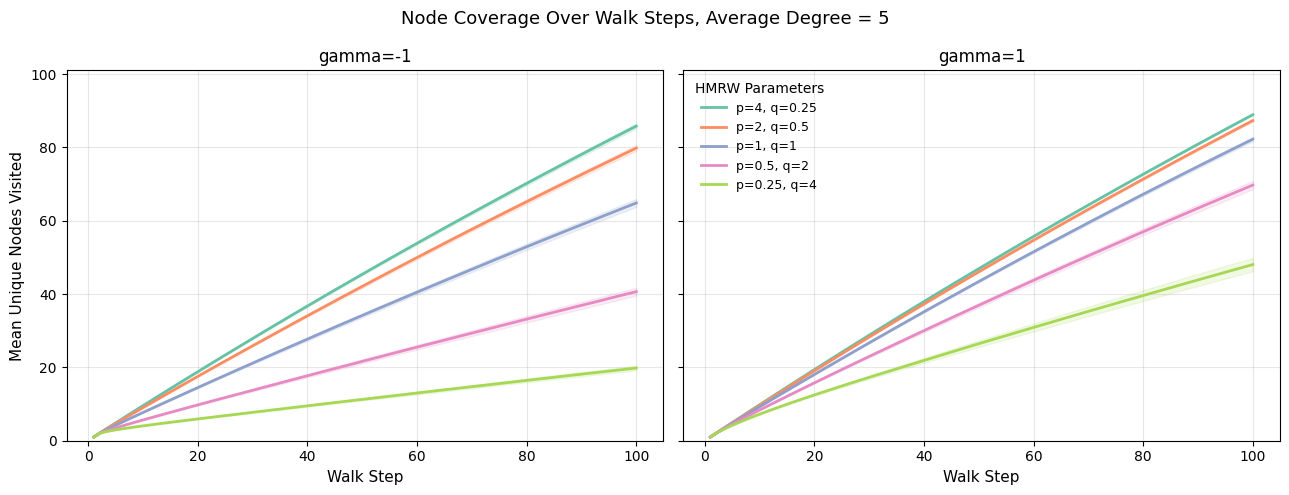

In [32]:
pq_grid = [
    (0.25, 4),
    (0.5, 2),
    (1, 1),
    (2, 0.5),
    (4, 0.25)
]

# Node coverage from cached walks (no reruns)
walk_cache_cov = walk_5_cache_cov
results_dir = results_5_dir

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, gamma_val in zip(axes, [-1.0, 1.0]):
    for i, (p_i, q_i) in enumerate(pq_grid[::-1]):
        curves = [walk_cache_cov[(gamma_val, p_i, q_i, g)]["node"] for g in range(10)]
        C = np.vstack(curves)
        mean_c, std_c = C.mean(axis=0), C.std(axis=0)
        steps = np.arange(1, len(mean_c) + 1)
        c = colors[i % len(colors)]
        ax.plot(steps, mean_c, color=c, lw=2, label=f"p={p_i}, q={q_i}")
        ax.fill_between(steps, mean_c - std_c, mean_c + std_c, color=c, alpha=0.15)
    ax.set_xlabel("Walk Step", fontsize=11)
    ax.set_title(f"gamma={gamma_val:.0f}", fontsize=12)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Mean Unique Nodes Visited", fontsize=11)
axes[1].legend(frameon=False, title="HMRW Parameters", fontsize=9)
axes[1].set_ylim(0.0, 101)
fig.suptitle("Node Coverage Over Walk Steps, Average Degree = 5", fontsize=13)
fig.tight_layout()
fig.savefig(results_dir / "node_coverage_pq_gamma_subplots.png", dpi=300, bbox_inches="tight")
plt.show()

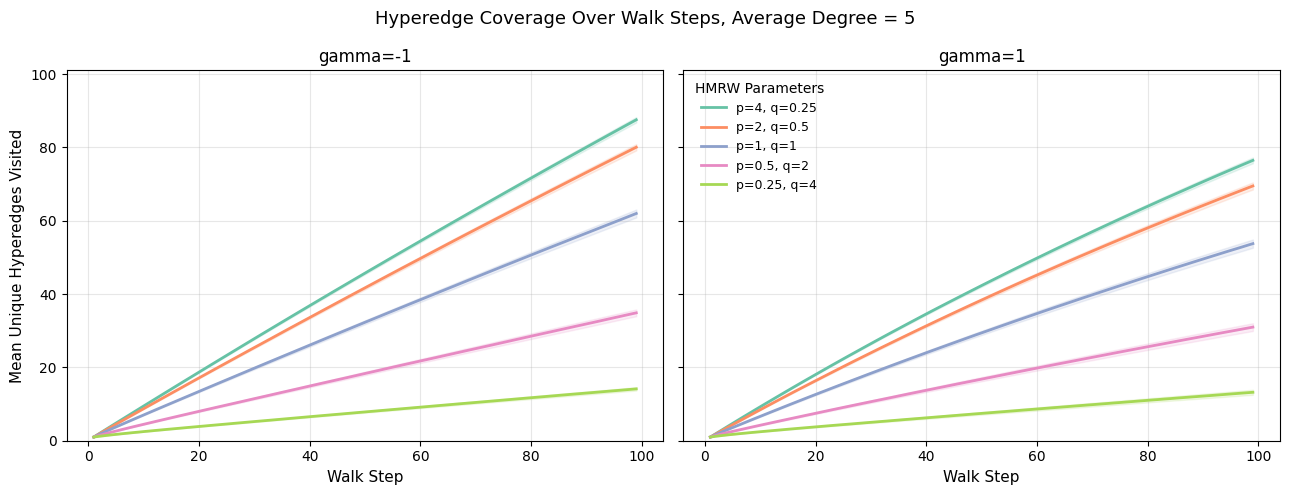

In [31]:
# Hyperedge coverage from cached walks (no reruns)
walk_cache_cov = walk_5_cache_cov
results_dir = results_5_dir

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, gamma_val in zip(axes, [-1.0, 1.0]):
    for i, (p_i, q_i) in enumerate(pq_grid[::-1]):
        curves = [walk_cache_cov[(gamma_val, p_i, q_i, g)]["hyper"] for g in range(10)]
        C = np.vstack(curves)
        mean_c, std_c = C.mean(axis=0), C.std(axis=0)
        steps = np.arange(1, len(mean_c) + 1)
        c = colors[i % len(colors)]
        ax.plot(steps, mean_c, color=c, lw=2, label=f"p={p_i}, q={q_i}")
        ax.fill_between(steps, mean_c - std_c, mean_c + std_c, color=c, alpha=0.15)
    ax.set_xlabel("Walk Step", fontsize=11)
    ax.set_title(f"gamma={gamma_val:.0f}", fontsize=12)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Mean Unique Hyperedges Visited", fontsize=11)
axes[1].legend(frameon=False, title="HMRW Parameters", fontsize=9)
axes[1].set_ylim(0.0, 101)
fig.suptitle("Hyperedge Coverage Over Walk Steps, Average Degree = 5", fontsize=13)
fig.tight_layout()
fig.savefig(results_dir / "hyperedge_coverage_pq_gamma_subplots.png", dpi=300, bbox_inches="tight")
plt.show()

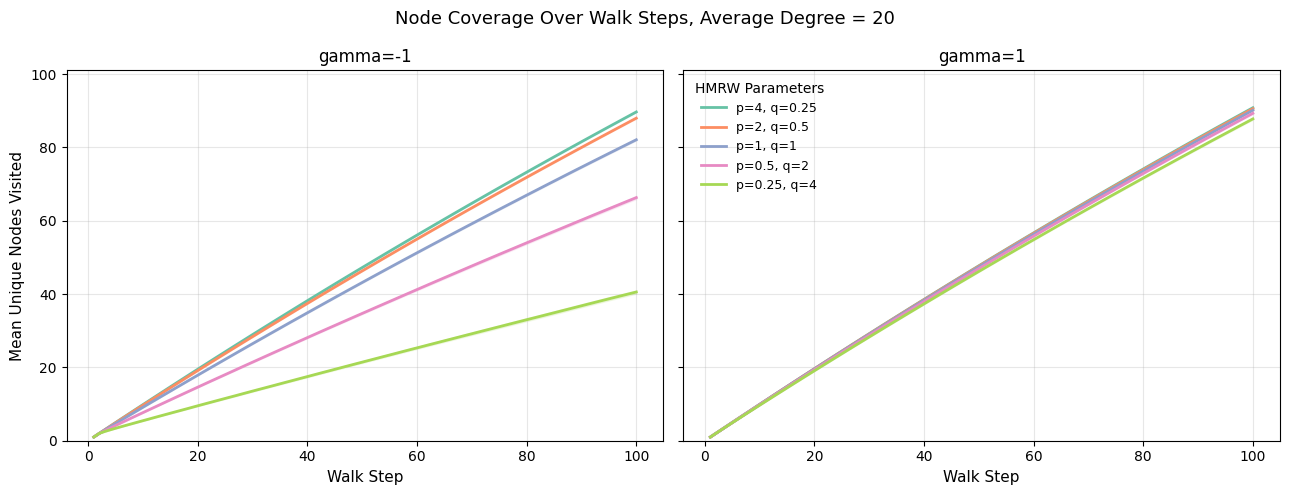

In [30]:
# Node coverage from cached walks (no reruns)
walk_cache_cov = walk_20_cache_cov
results_dir = results_20_dir

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, gamma_val in zip(axes, [-1.0, 1.0]):
    for i, (p_i, q_i) in enumerate(pq_grid[::-1]):
        curves = [walk_cache_cov[(gamma_val, p_i, q_i, g)]["node"] for g in range(10)]
        C = np.vstack(curves)
        mean_c, std_c = C.mean(axis=0), C.std(axis=0)
        steps = np.arange(1, len(mean_c) + 1)
        c = colors[i % len(colors)]
        ax.plot(steps, mean_c, color=c, lw=2, label=f"p={p_i}, q={q_i}")
        ax.fill_between(steps, mean_c - std_c, mean_c + std_c, color=c, alpha=0.15)
    ax.set_xlabel("Walk Step", fontsize=11)
    ax.set_title(f"gamma={gamma_val:.0f}", fontsize=12)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Mean Unique Nodes Visited", fontsize=11)
axes[1].legend(frameon=False, title="HMRW Parameters", fontsize=9)
axes[1].set_ylim(0.0, 101)
fig.suptitle("Node Coverage Over Walk Steps, Average Degree = 20", fontsize=13)
fig.tight_layout()
fig.savefig(results_dir / "node_coverage_pq_gamma_subplots.png", dpi=300, bbox_inches="tight")
plt.show()

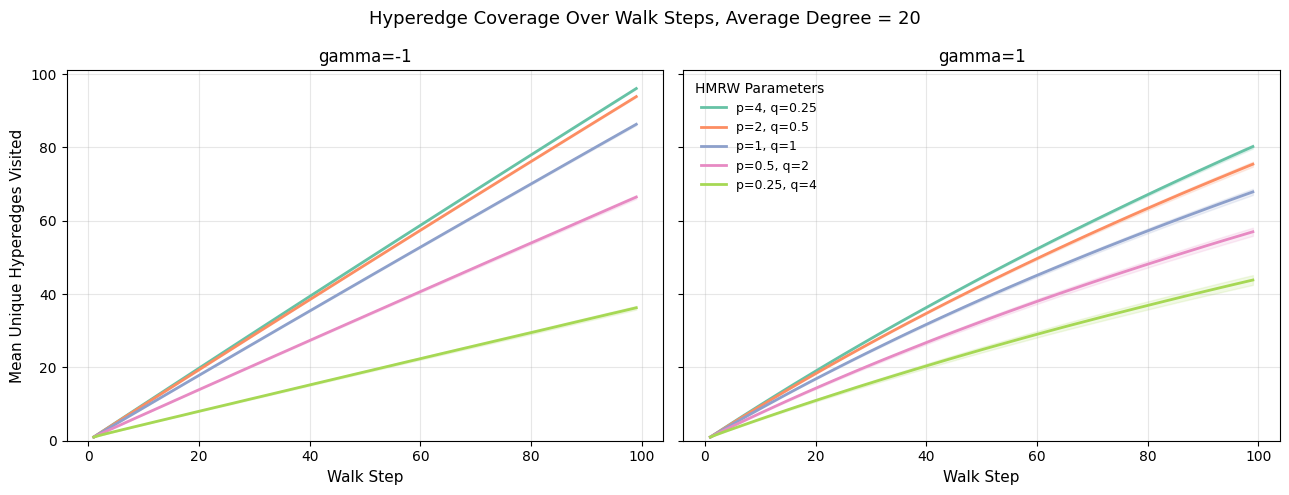

In [29]:
# Hyperedge coverage from cached walks (no reruns)
walk_cache_cov = walk_20_cache_cov
results_dir = results_20_dir

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, gamma_val in zip(axes, [-1.0, 1.0]):
    for i, (p_i, q_i) in enumerate(pq_grid[::-1]):
        curves = [walk_cache_cov[(gamma_val, p_i, q_i, g)]["hyper"] for g in range(10)]
        C = np.vstack(curves)
        mean_c, std_c = C.mean(axis=0), C.std(axis=0)
        steps = np.arange(1, len(mean_c) + 1)
        c = colors[i % len(colors)]
        ax.plot(steps, mean_c, color=c, lw=2, label=f"p={p_i}, q={q_i}")
        ax.fill_between(steps, mean_c - std_c, mean_c + std_c, color=c, alpha=0.15)
    ax.set_xlabel("Walk Step", fontsize=11)
    ax.set_title(f"gamma={gamma_val:.0f}", fontsize=12)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Mean Unique Hyperedges Visited", fontsize=11)
axes[1].legend(frameon=False, title="HMRW Parameters", fontsize=9)
axes[1].set_ylim(0.0, 101)
fig.suptitle("Hyperedge Coverage Over Walk Steps, Average Degree = 20", fontsize=13)
fig.tight_layout()
fig.savefig(results_dir / "hyperedge_coverage_pq_gamma_subplots.png", dpi=300, bbox_inches="tight")
plt.show()

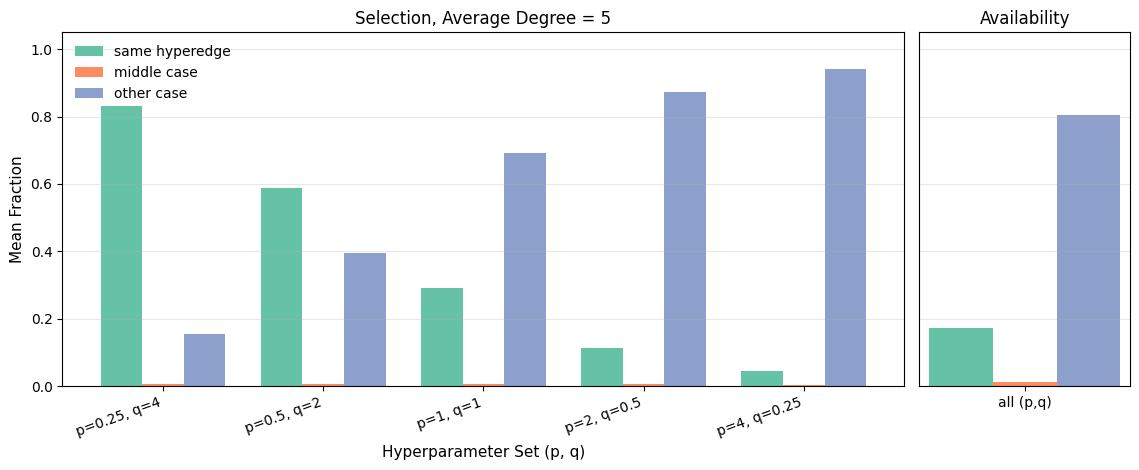

In [39]:
# Stage-1 selected vs possible from cached walks (no reruns)
walk_cache_cov = walk_5_cache_cov
results_dir = results_5_dir

gamma_diag = -1.0
case_names = ["same hyperedge", "middle case", "other case"]
group_labels = [f"p={p_i}, q={q_i}" for (p_i, q_i) in pq_grid]

selected_vals = []
possible_vals = []
for p_i, q_i in pq_grid:
    selected_curves = [walk_cache_cov[(gamma_diag, p_i, q_i, g)]["case"] for g in range(10)]
    possible_curves = [walk_cache_cov[(gamma_diag, p_i, q_i, g)]["possible"] for g in range(10)]
    selected_vals.append(np.stack(selected_curves, axis=0).mean(axis=(0, 1)))
    possible_vals.append(np.stack(possible_curves, axis=0).mean(axis=(0, 1)))

selected_vals = np.asarray(selected_vals)
possible_vals = np.asarray(possible_vals)

rows = []
for i, (p_i, q_i) in enumerate(pq_grid):
    rows.append({
        "p": p_i, "q": q_i,
        "selected_same": selected_vals[i, 0], "selected_middle": selected_vals[i, 1], "selected_other": selected_vals[i, 2],
        "possible_same": possible_vals[i, 0], "possible_middle": possible_vals[i, 1], "possible_other": possible_vals[i, 2],
    }) 
pd.DataFrame(rows).to_csv(results_dir
                          / "stage1_transition_cases_selected_vs_possible.csv", index=False)

avail_one = possible_vals.mean(axis=0)
ymax = max(float(selected_vals.max()), float(avail_one.max()))

x = np.arange(len(pq_grid)); bar_w = 0.26
case_colors = ["#66c2a5", "#fc8d62", "#8da0cb"]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [4, 1]})
for j, name in enumerate(case_names):
    axes[0].bar(x + (j - 1) * bar_w, selected_vals[:, j], width=bar_w, color=case_colors[j], label=name)
axes[0].set_ylim(0.0, 1.05)
axes[0].set_ylabel("Mean Fraction", fontsize=11)
axes[0].set_xlabel("Hyperparameter Set (p, q)", fontsize=11)
axes[0].set_title(f"Selection, Average Degree = 5", fontsize=12)
axes[0].grid(axis="y", alpha=0.3)
axes[0].set_xticks(x)
axes[0].set_xticklabels(group_labels, rotation=20, ha="right")
axes[0].legend(frameon=False, loc="upper left")

x2 = np.array([0.0])
for j, _ in enumerate(case_names):
    axes[1].bar(x2 + (j - 1) * bar_w, [avail_one[j]], width=bar_w, color=case_colors[j])
axes[1].set_ylim(0.0, 1.05)
axes[1].set_title("Availability", fontsize=12)
axes[1].grid(axis="y", alpha=0.3)
axes[1].set_xticks([0.0])
axes[1].set_xticklabels(["all (p,q)"])
axes[1].tick_params(axis="y", left=False, labelleft=False)

fig.tight_layout()
fig.savefig(results_dir / "stage1_transition_cases_barplot_selected_vs_possible.png", dpi=300, bbox_inches="tight")
plt.show()

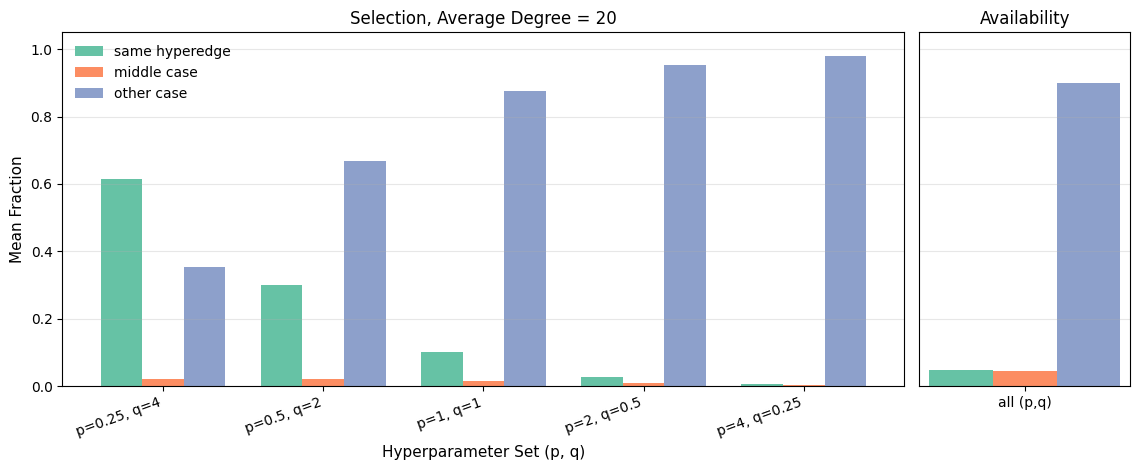

In [40]:
# Stage-1 selected vs possible from cached walks (no reruns)
walk_cache_cov = walk_20_cache_cov
results_dir = results_20_dir

gamma_diag = -1.0
case_names = ["same hyperedge", "middle case", "other case"]
group_labels = [f"p={p_i}, q={q_i}" for (p_i, q_i) in pq_grid]

selected_vals = []
possible_vals = []
for p_i, q_i in pq_grid:
    selected_curves = [walk_cache_cov[(gamma_diag, p_i, q_i, g)]["case"] for g in range(10)]
    possible_curves = [walk_cache_cov[(gamma_diag, p_i, q_i, g)]["possible"] for g in range(10)]
    selected_vals.append(np.stack(selected_curves, axis=0).mean(axis=(0, 1)))
    possible_vals.append(np.stack(possible_curves, axis=0).mean(axis=(0, 1)))

selected_vals = np.asarray(selected_vals)
possible_vals = np.asarray(possible_vals)

rows = []
for i, (p_i, q_i) in enumerate(pq_grid):
    rows.append({
        "p": p_i, "q": q_i,
        "selected_same": selected_vals[i, 0], "selected_middle": selected_vals[i, 1], "selected_other": selected_vals[i, 2],
        "possible_same": possible_vals[i, 0], "possible_middle": possible_vals[i, 1], "possible_other": possible_vals[i, 2],
    })
pd.DataFrame(rows).to_csv(results_dir
                          / "stage1_transition_cases_selected_vs_possible.csv", index=False)

avail_one = possible_vals.mean(axis=0)
ymax = max(float(selected_vals.max()), float(avail_one.max()))

x = np.arange(len(pq_grid)); bar_w = 0.26
case_colors = ["#66c2a5", "#fc8d62", "#8da0cb"]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [4, 1]})
for j, name in enumerate(case_names):
    axes[0].bar(x + (j - 1) * bar_w, selected_vals[:, j], width=bar_w, color=case_colors[j], label=name)
axes[0].set_ylim(0.0, 1.05)
axes[0].set_ylabel("Mean Fraction", fontsize=11)
axes[0].set_xlabel("Hyperparameter Set (p, q)", fontsize=11)
axes[0].set_title(f"Selection, Average Degree = 20", fontsize=12)
axes[0].grid(axis="y", alpha=0.3)
axes[0].set_xticks(x)
axes[0].set_xticklabels(group_labels, rotation=20, ha="right")
axes[0].legend(frameon=False, loc="upper left")

x2 = np.array([0.0])
for j, _ in enumerate(case_names):
    axes[1].bar(x2 + (j - 1) * bar_w, [avail_one[j]], width=bar_w, color=case_colors[j])
axes[1].set_ylim(0.0, 1.05)
axes[1].set_title("Availability", fontsize=12)
axes[1].grid(axis="y", alpha=0.3)
axes[1].set_xticks([0.0])
axes[1].set_xticklabels(["all (p,q)"])
axes[1].tick_params(axis="y", left=False, labelleft=False)

fig.tight_layout()
fig.savefig(results_dir / "stage1_transition_cases_barplot_selected_vs_possible.png", dpi=300, bbox_inches="tight")
plt.show()

Loaded community walk cache: results/walk_exploration/avgdeg_ncom_aff09/walk_cache_comm.pkl


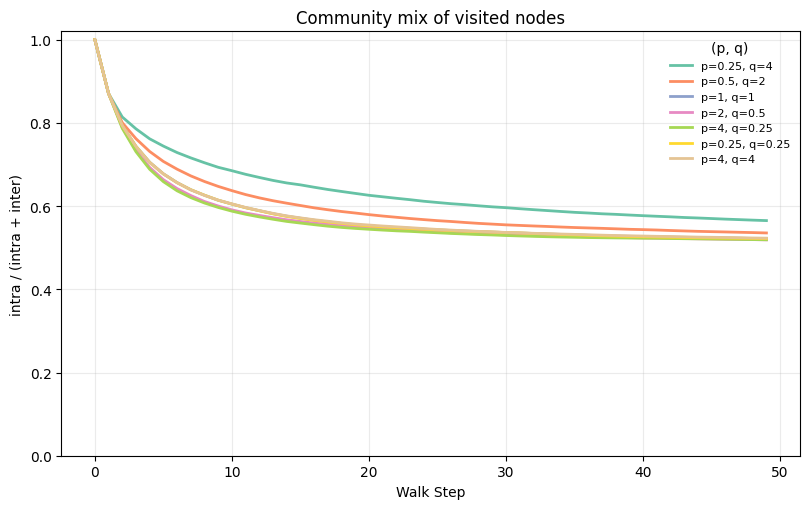

In [ ]:
# Community-aware node coverage over walk steps (from cached walks)

# pq_grid_mix = [(0.25, 4.0), (0.5, 2.0), (1.0, 1.0), (2.0, 0.5), (4.0, 0.25)]
pq_comm_grid = [
    (0.25, 4),
    (0.5, 2),
    (1, 1),
    (2, 0.5),
    (4, 0.25),
    (0.25, 0.25),
    (4, 4)
]

colors = plt.get_cmap("Set2").colors

results_comm_dir = results_ncom_aff09_dir
# Load community cache if needed
walk_cache_comm_path = results_comm_dir / "walk_cache_comm.pkl"
with open(walk_cache_comm_path, "rb") as f:
    walk_cache_comm = pickle.load(f)
print(f"Loaded community walk cache: {walk_cache_comm_path}")

n_graphs_comm = len(Hs_y_ncom_aff09)

gamma_val = -1.0
fig, ax = plt.subplots(1, 1, figsize=(8.2, 5.2))

n_steps_toplot = 50
for i, (p_i, q_i) in enumerate(pq_comm_grid):
    intra_curves = [walk_cache_comm[(gamma_val, p_i, q_i, g)]["intra"][:n_steps_toplot] for g in range(n_graphs_comm)]
    inter_curves = [walk_cache_comm[(gamma_val, p_i, q_i, g)]["inter"][:n_steps_toplot] for g in range(n_graphs_comm)]

    mean_intra = np.vstack(intra_curves).mean(axis=0)
    mean_inter = np.vstack(inter_curves).mean(axis=0)
    total = mean_intra + mean_inter
    ratio = np.divide(mean_intra, total, out=np.zeros_like(mean_intra), where=total > 0)

    steps = np.arange(len(ratio))
    c = colors[i % len(colors)]
    ax.plot(steps, ratio, color=c, lw=2, label=f"p={p_i}, q={q_i}")

ax.set_xlabel("Walk Step")
ax.set_ylabel(r"intra / (intra + inter)")
ax.set_title("Community mix of visited nodes")
ax.set_ylim(0.0, 1.02)
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8, title="(p, q)", loc="best")

fig.tight_layout()
fig.savefig(results_comm_dir / "community_aware_node_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

Loaded community walk cache: results/walk_exploration/avgdeg_ncom_aff06/walk_cache_comm.pkl


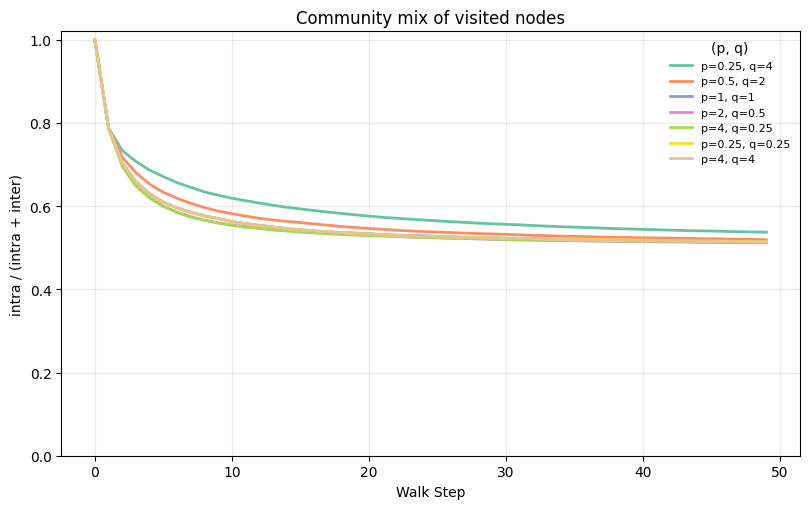

In [ ]:
# Community-aware node coverage over walk steps (from cached walks)

# pq_grid_mix = [(0.25, 4.0), (0.5, 2.0), (1.0, 1.0), (2.0, 0.5), (4.0, 0.25)]
pq_comm_grid = [
    (0.25, 4),
    (0.5, 2),
    (1, 1),
    (2, 0.5),
    (4, 0.25),
    (0.25, 0.25),
    (4, 4)
]

colors = plt.get_cmap("Set2").colors

results_comm_dir = results_ncom_aff06_dir
# Load community cache if needed
walk_cache_comm_path = results_comm_dir / "walk_cache_comm.pkl"
with open(walk_cache_comm_path, "rb") as f:
    walk_cache_comm = pickle.load(f)
print(f"Loaded community walk cache: {walk_cache_comm_path}")

n_graphs_comm = len(Hs_y_ncom_aff06)

gamma_val = -1.0
fig, ax = plt.subplots(1, 1, figsize=(8.2, 5.2))

n_steps_toplot = 50
for i, (p_i, q_i) in enumerate(pq_comm_grid):
    intra_curves = [walk_cache_comm[(gamma_val, p_i, q_i, g)]["intra"][:n_steps_toplot] for g in range(n_graphs_comm)]
    inter_curves = [walk_cache_comm[(gamma_val, p_i, q_i, g)]["inter"][:n_steps_toplot] for g in range(n_graphs_comm)]

    mean_intra = np.vstack(intra_curves).mean(axis=0)
    mean_inter = np.vstack(inter_curves).mean(axis=0)
    total = mean_intra + mean_inter 
    ratio = np.divide(mean_intra, total, out=np.zeros_like(mean_intra), where=total > 0)

    steps = np.arange(len(ratio))
    c = colors[i % len(colors)]
    ax.plot(steps, ratio, color=c, lw=2, label=f"p={p_i}, q={q_i}")

ax.set_xlabel("Walk Step")
ax.set_ylabel(r"intra / (intra + inter)")
ax.set_title("Community mix of visited nodes")
ax.set_ylim(0.0, 1.02)
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8, title="(p, q)", loc="best")

fig.tight_layout()
fig.savefig(results_comm_dir / "community_aware_node_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

Loaded: results/walk_exploration/avgdeg_ncom_aff09/walk_cache_comm.pkl
Loaded: results/walk_exploration/avgdeg_ncom_aff06/walk_cache_comm.pkl


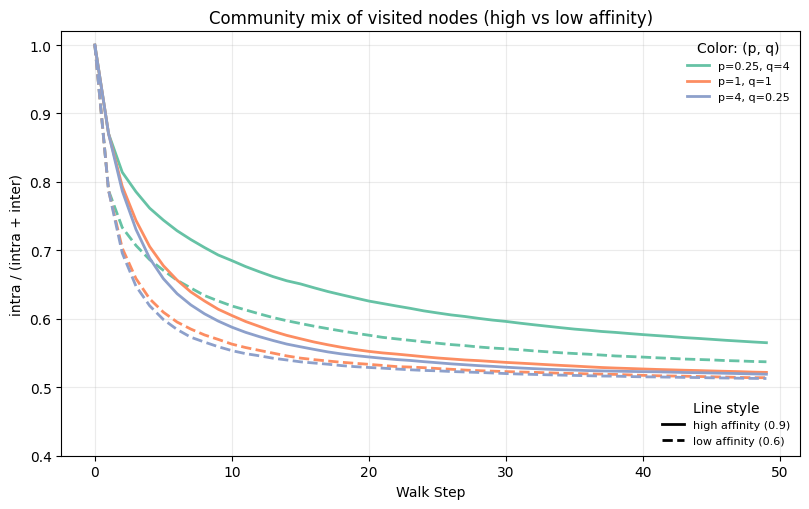

In [ ]:
# Joint community-mix plot: high vs low affinity (same (p, q) grid as cells above)
from matplotlib.lines import Line2D

pq_comm_grid = [
    (0.25, 4),
    # (0.5, 2),
    (1, 1),
    # (2, 0.5),
    (4, 0.25),
    # (0.25, 0.25),
    # (4, 4),
]

colors = plt.get_cmap("Set2").colors
gamma_val = -1.0
n_steps_toplot = 50

walk_cache_high_path = results_ncom_aff09_dir / "walk_cache_comm.pkl"
walk_cache_low_path = results_ncom_aff06_dir / "walk_cache_comm.pkl"
with open(walk_cache_high_path, "rb") as f:
    walk_cache_high = pickle.load(f)
with open(walk_cache_low_path, "rb") as f:
    walk_cache_low = pickle.load(f)
print(f"Loaded: {walk_cache_high_path}")
print(f"Loaded: {walk_cache_low_path}")

n_g_high = len(Hs_y_ncom_aff09)
n_g_low = len(Hs_y_ncom_aff06)

fig, ax = plt.subplots(1, 1, figsize=(8.2, 5.2))

for i, (p_i, q_i) in enumerate(pq_comm_grid):
    c = colors[i % len(colors)]
    key = (gamma_val, p_i, q_i)

    intra_h = [walk_cache_high[(*key, g)]["intra"][:n_steps_toplot] for g in range(n_g_high)]
    inter_h = [walk_cache_high[(*key, g)]["inter"][:n_steps_toplot] for g in range(n_g_high)]
    mean_intra_h = np.vstack(intra_h).mean(axis=0)
    mean_inter_h = np.vstack(inter_h).mean(axis=0)
    total_h = mean_intra_h + mean_inter_h
    ratio_h = np.divide(mean_intra_h, total_h, out=np.zeros_like(mean_intra_h), where=total_h > 0)

    intra_l = [walk_cache_low[(*key, g)]["intra"][:n_steps_toplot] for g in range(n_g_low)]
    inter_l = [walk_cache_low[(*key, g)]["inter"][:n_steps_toplot] for g in range(n_g_low)]
    mean_intra_l = np.vstack(intra_l).mean(axis=0)
    mean_inter_l = np.vstack(inter_l).mean(axis=0)
    total_l = mean_intra_l + mean_inter_l
    ratio_l = np.divide(mean_intra_l, total_l, out=np.zeros_like(mean_intra_l), where=total_l > 0)

    steps_h = np.arange(len(ratio_h))
    steps_l = np.arange(len(ratio_l))
    ax.plot(steps_h, ratio_h, color=c, lw=2, linestyle="-")
    ax.plot(steps_l, ratio_l, color=c, lw=2, linestyle="--")

ax.set_xlabel("Walk Step")
ax.set_ylabel(r"intra / (intra + inter)")
ax.set_title("Community mix of visited nodes (high vs low affinity)")
ax.set_ylim(0.4, 1.02)
ax.grid(alpha=0.25)

color_handles = [
    Line2D([0], [0], color=colors[i % len(colors)], lw=2, linestyle="-", label=f"p={p_i}, q={q_i}")
    for i, (p_i, q_i) in enumerate(pq_grid)
]
style_handles = [
    Line2D([0], [0], color="black", lw=2, linestyle="-", label="high affinity (0.9)"),
    Line2D([0], [0], color="black", lw=2, linestyle="--", label="low affinity (0.6)"),
]
leg1 = ax.legend(handles=color_handles, title="Color: (p, q)", frameon=False, fontsize=8, loc="upper right")
ax.add_artist(leg1)
ax.legend(handles=style_handles, title="Line style", frameon=False, fontsize=8, loc="lower right")

results_joint_dir = Path("results") / "walk_exploration" / "avgdeg_ncom_joint"
results_joint_dir.mkdir(parents=True, exist_ok=True)
fig.tight_layout()
fig.savefig(results_joint_dir / "community_aware_node_coverage_joint.png", dpi=300, bbox_inches="tight")
plt.show()

Loaded: results/walk_exploration/avgdeg5_aff09/walk_cache_comm.pkl, results/walk_exploration/avgdeg5_aff06/walk_cache_comm.pkl
Loaded: results/walk_exploration/avgdeg20_aff09/walk_cache_comm.pkl, results/walk_exploration/avgdeg20_aff06/walk_cache_comm.pkl


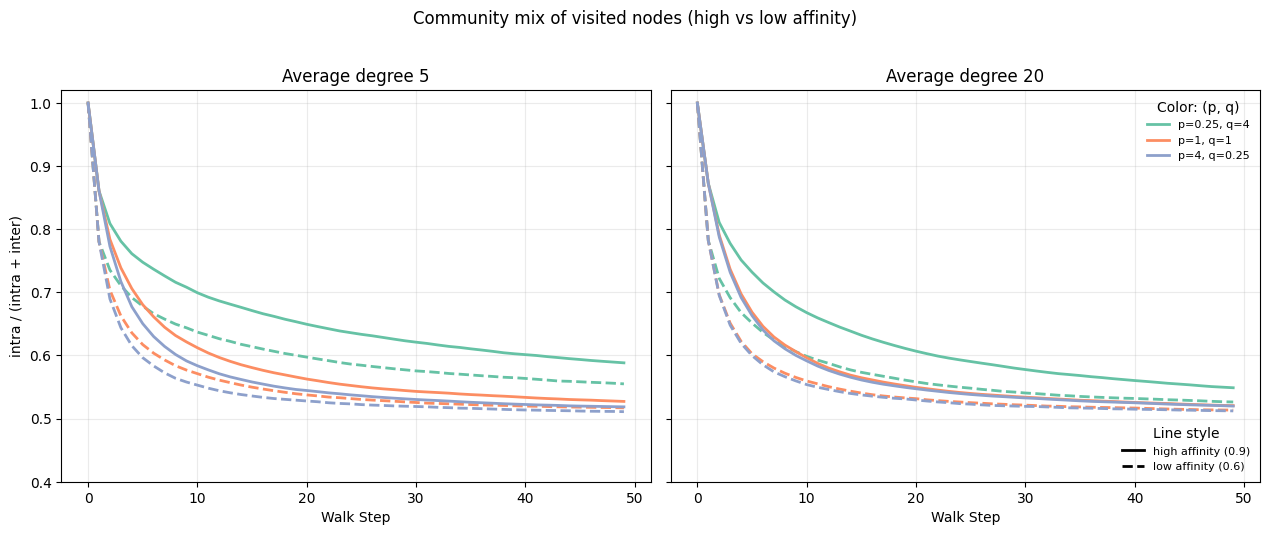

In [65]:
# Joint community-mix plot: avgdeg 5 vs 20 (two panels, same (p, q) grid)
from matplotlib.lines import Line2D

pq_comm_grid = [
    (0.25, 4),
    (1, 1),
    (4, 0.25),
]

colors = plt.get_cmap("Set2").colors
gamma_val = -1.0
n_steps_toplot = 50

walk_cache_5_high_path = results_avgdeg5_aff09_dir / "walk_cache_comm.pkl"
walk_cache_5_low_path = results_avgdeg5_aff06_dir / "walk_cache_comm.pkl"
walk_cache_20_high_path = results_avgdeg20_aff09_dir / "walk_cache_comm.pkl"
walk_cache_20_low_path = results_avgdeg20_aff06_dir / "walk_cache_comm.pkl"

with open(walk_cache_5_high_path, "rb") as f:
    walk_cache_5_high = pickle.load(f)
with open(walk_cache_5_low_path, "rb") as f:
    walk_cache_5_low = pickle.load(f)
with open(walk_cache_20_high_path, "rb") as f:
    walk_cache_20_high = pickle.load(f)
with open(walk_cache_20_low_path, "rb") as f:
    walk_cache_20_low = pickle.load(f)
print(f"Loaded: {walk_cache_5_high_path}, {walk_cache_5_low_path}")
print(f"Loaded: {walk_cache_20_high_path}, {walk_cache_20_low_path}")

n_g_high = 5
n_g_low = 5


def _plot_joint_panel(ax, walk_cache_high, walk_cache_low):
    for i, (p_i, q_i) in enumerate(pq_comm_grid):
        c = colors[i % len(colors)]
        key = (gamma_val, p_i, q_i)

        intra_h = [walk_cache_high[(*key, g)]["intra"][:n_steps_toplot] for g in range(n_g_high)]
        inter_h = [walk_cache_high[(*key, g)]["inter"][:n_steps_toplot] for g in range(n_g_high)]
        mean_intra_h = np.vstack(intra_h).mean(axis=0)
        mean_inter_h = np.vstack(inter_h).mean(axis=0)
        total_h = mean_intra_h + mean_inter_h
        ratio_h = np.divide(mean_intra_h, total_h, out=np.zeros_like(mean_intra_h), where=total_h > 0)

        intra_l = [walk_cache_low[(*key, g)]["intra"][:n_steps_toplot] for g in range(n_g_low)]
        inter_l = [walk_cache_low[(*key, g)]["inter"][:n_steps_toplot] for g in range(n_g_low)]
        mean_intra_l = np.vstack(intra_l).mean(axis=0)
        mean_inter_l = np.vstack(inter_l).mean(axis=0)
        total_l = mean_intra_l + mean_inter_l
        ratio_l = np.divide(mean_intra_l, total_l, out=np.zeros_like(mean_intra_l), where=total_l > 0)

        steps_h = np.arange(len(ratio_h))
        steps_l = np.arange(len(ratio_l))
        ax.plot(steps_h, ratio_h, color=c, lw=2, linestyle="-")
        ax.plot(steps_l, ratio_l, color=c, lw=2, linestyle="--")

    ax.set_xlabel("Walk Step")
    ax.set_ylim(0.4, 1.02)
    ax.grid(alpha=0.25)


fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.2), sharey=True)
_plot_joint_panel(axes[0], walk_cache_5_high, walk_cache_5_low)
axes[0].set_ylabel(r"intra / (intra + inter)")
axes[0].set_title("Average degree 5")
_plot_joint_panel(axes[1], walk_cache_20_high, walk_cache_20_low)
axes[1].set_title("Average degree 20")

color_handles = [
    Line2D([0], [0], color=colors[i % len(colors)], lw=2, linestyle="-", label=f"p={p_i}, q={q_i}")
    for i, (p_i, q_i) in enumerate(pq_comm_grid)
]
style_handles = [
    Line2D([0], [0], color="black", lw=2, linestyle="-", label="high affinity (0.9)"),
    Line2D([0], [0], color="black", lw=2, linestyle="--", label="low affinity (0.6)"),
]
leg1 = axes[1].legend(handles=color_handles, title="Color: (p, q)", frameon=False, fontsize=8, loc="upper right")
axes[1].add_artist(leg1)
axes[1].legend(handles=style_handles, title="Line style", frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Community mix of visited nodes (high vs low affinity)", fontsize=12, y=1.02)

results_joint_dir = Path("results") / "walk_exploration" / "avgdeg_ncom_joint"
results_joint_dir.mkdir(parents=True, exist_ok=True)
fig.tight_layout()
fig.savefig(results_joint_dir / "community_aware_node_coverage_joint_avgdeg5_20.png", dpi=300, bbox_inches="tight")
plt.show()
